In [4]:
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
customer_performance = pd.DataFrame({
    "Customer": ["Amazon", "Unknown", "Zalando", "Otto"],
    "Total_Revenue": [2700, 2000, 850, 650],
    "Avg_Revenue": [1350, 2000, 850, 650],
    "Shipments": [2, 1, 1, 1]
})

<function matplotlib.pyplot.show(close=None, block=None)>

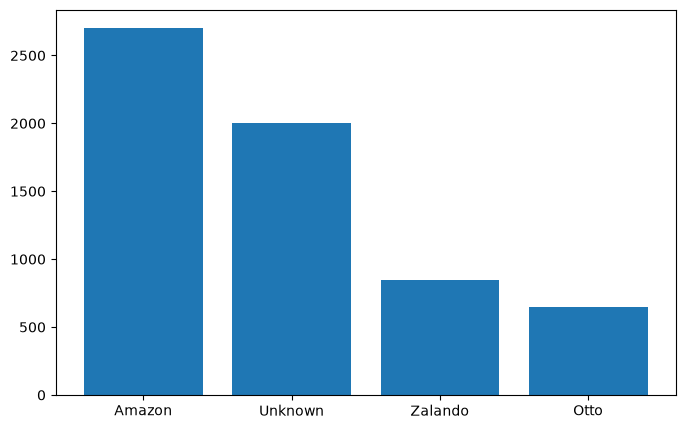

In [28]:
fig, ax = plt.subplots(figsize=(8,5))
ax.bar (
    customer_performance["Customer"],
    customer_performance["Total_Revenue"]
)
plt.show

### Exercise 02.06.02 — Professional Bar Charts

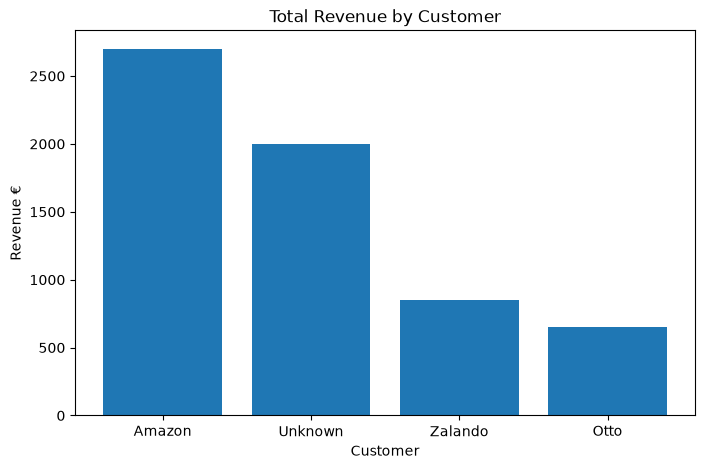

In [30]:
fig, ax = plt.subplots(figsize=(8,5))
ax.bar (
    customer_performance["Customer"],
    customer_performance["Total_Revenue"]
)

ax.set_title("Total Revenue by Customer")
ax.set_xlabel("Customer")
ax.set_ylabel("Revenue €")
plt.show()

#### 02.06.02B — Adding Values Above Bars

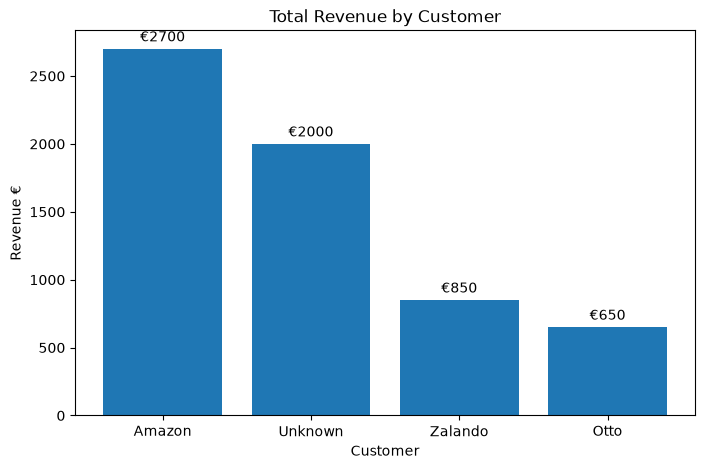

In [39]:
fig, ax = plt.subplots(figsize=(8,5))
bars = ax.bar (
    customer_performance["Customer"],
    customer_performance["Total_Revenue"]
)
ax.bar_label(
    bars,
    fmt="€%.0f",
    padding=3
)

ax.set_title("Total Revenue by Customer")
ax.set_xlabel("Customer")
ax.set_ylabel("Revenue €")
plt.show()


### Exercise 02.06.02C — Highlighting Key Business Insights

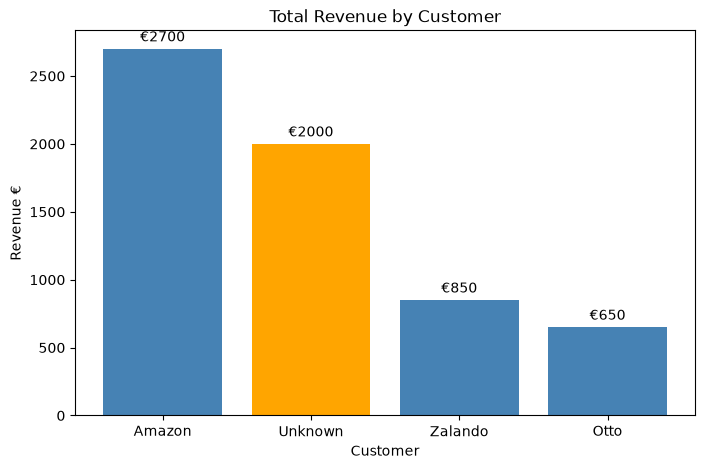

In [48]:
fig, ax = plt.subplots(figsize=(8,5))
colors = ["orange" if customer == "Unknown" else "steelblue"
          for customer in customer_performance["Customer"]]
bars = ax.bar (
    customer_performance["Customer"],
    customer_performance["Total_Revenue"],
    color = colors
    

)
ax.bar_label(
    bars,
    fmt="€%.0f",
    padding=3
)

ax.set_title("Total Revenue by Customer")
ax.set_xlabel("Customer")
ax.set_ylabel("Revenue €")
plt.show()

### 02.06.02D — Adding Business Insights to Charts

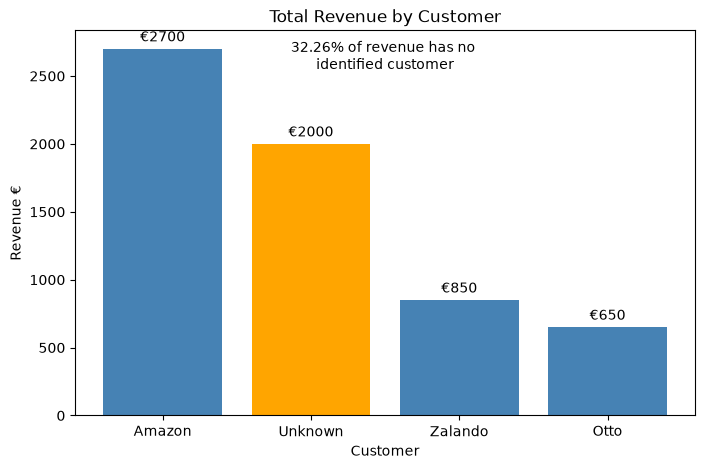

In [62]:
total_revenue = customer_performance["Total_Revenue"].sum()
unknown_customer= customer_performance[customer_performance["Customer"] == "Unknown"]
unknown_revenue = unknown_customer["Total_Revenue"].sum()
unknown_share = unknown_revenue / total_revenue * 100

fig, ax = plt.subplots(figsize=(8,5))
colors = ["orange" if customer == "Unknown" else "steelblue"
          for customer in customer_performance["Customer"]]
bars = ax.bar (
    customer_performance["Customer"],
    customer_performance["Total_Revenue"],
    color = colors
    

)
ax.bar_label(
    bars,
    fmt="€%.0f",
    padding=3
)

ax.text(
    0.5,
    0.9,
    (f"{(unknown_share).round(2)}% of revenue has no \nidentified customer"),
    transform = ax.transAxes,
    ha="center"

)

ax.set_title("Total Revenue by Customer")
ax.set_xlabel("Customer")
ax.set_ylabel("Revenue €")
plt.show()

### 02.06.03 — Line Charts & Trend Analysis

In [63]:
shipment_trends = pd.DataFrame({
    "Month": ["Jan", "Feb", "Mar", "Apr", "May", "Jun"],
    "Shipments": [120, 145, 138, 170, 195, 220]
})

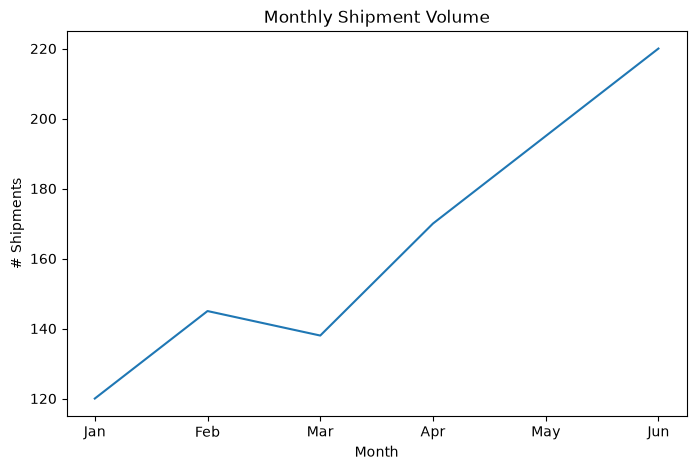

In [67]:
fig, ax = plt.subplots(figsize=(8,5))
ax.plot(
    shipment_trends["Month"],
    shipment_trends["Shipments"]
)
ax.set_title("Monthly Shipment Volume")
ax.set_xlabel("Month")
ax.set_ylabel("# Shipments")

plt.show()

### Exercise 02.06.03B — Improving Line Charts

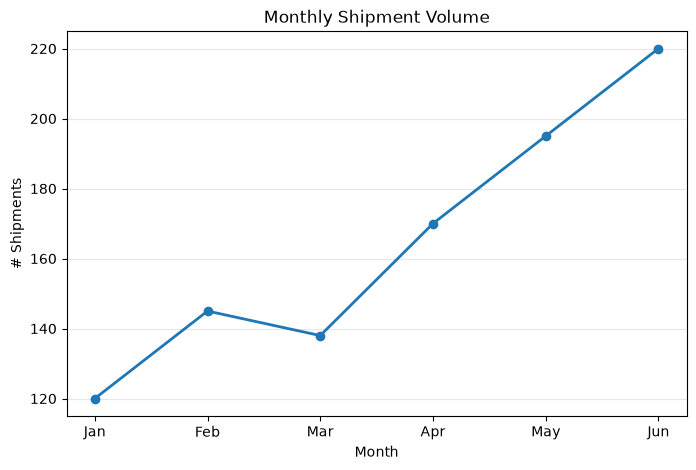

In [73]:

fig, ax = plt.subplots(figsize=(8,5))
ax.plot(
    shipment_trends["Month"],
    shipment_trends["Shipments"],
    marker="o",
    linestyle="-",
    linewidth=2
)

ax.grid(
    axis ="y",
    alpha=0.3
)

ax.set_title("Monthly Shipment Volume")
ax.set_xlabel("Month")
ax.set_ylabel("# Shipments")

plt.show()

plt.show()

### 02.06.03C — Month-over-Month Growth Analysis

In [77]:
customer_performance

,Customer,Total_Revenue,Avg_Revenue,Shipments
0,Amazon,2700,1350,2
1,Unknown,2000,2000,1
2,Zalando,850,850,1
3,Otto,650,650,1


In [80]:
shipment_trends

,Month,Shipments
0,Jan,120
1,Feb,145
2,Mar,138
3,Apr,170
4,May,195
5,Jun,220


In [81]:
shipment_trends["MoM_Growth"] = shipment_trends["Shipments"].pct_change()*100
shipment_trends

,Month,Shipments,MoM_Growth
0,Jan,120,NaN
1,Feb,145,20.833333
2,Mar,138,-4.827586
3,Apr,170,23.188406
4,May,195,14.705882
5,Jun,220,12.820513


### 02.06.03D — Visualizing Growth Rates

In [83]:
growth_data = shipment_trends.dropna(subset=["MoM_Growth"])
growth_data

,Month,Shipments,MoM_Growth
1,Feb,145,20.833333
2,Mar,138,-4.827586
3,Apr,170,23.188406
4,May,195,14.705882
5,Jun,220,12.820513


Text(0, 0.5, 'MoM growth (%)')

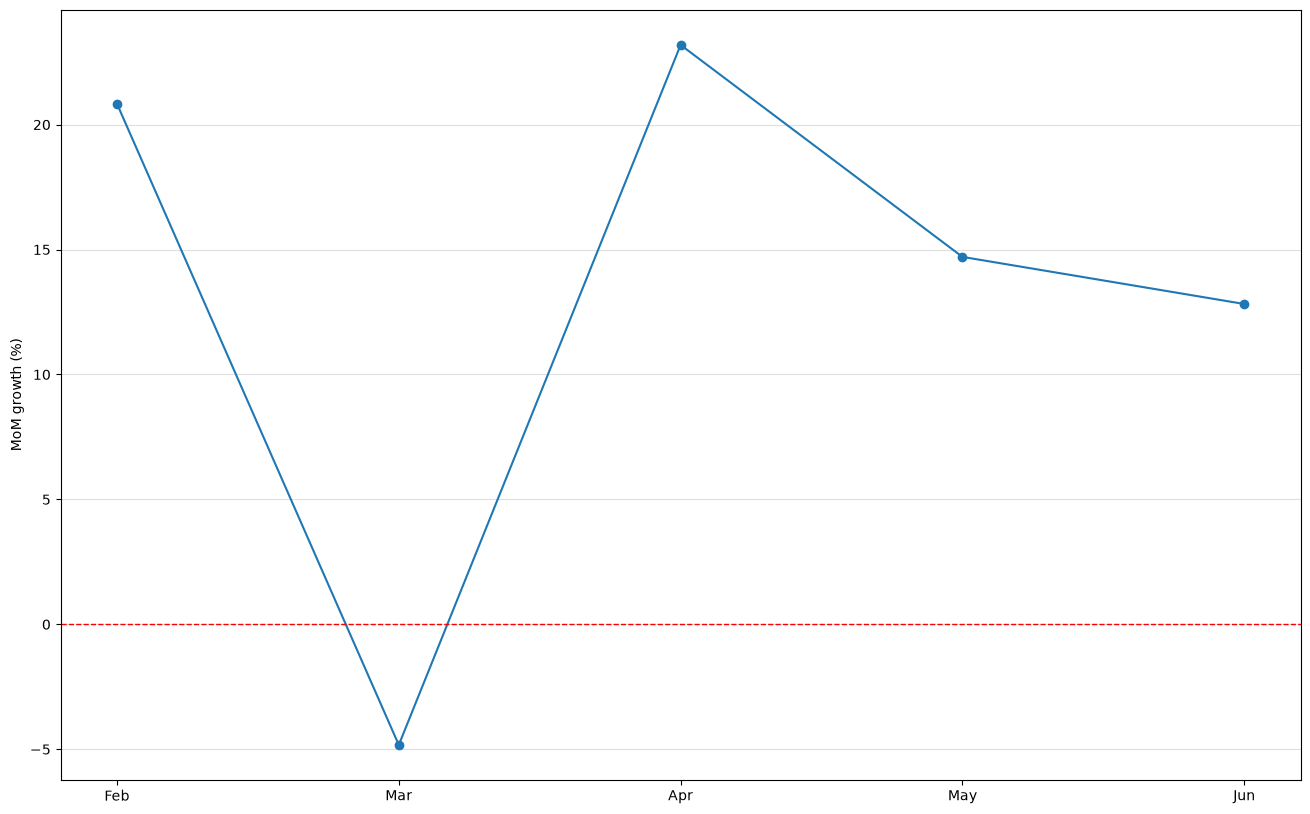

In [105]:
fig, ax = plt.subplots(figsize=(16,10))

ax.plot(
    growth_data["Month"],
    growth_data["MoM_Growth"],
    marker ="o",
    linestyle = "-",
)
ax.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth="1"
)

ax.grid(
    axis ="y",
    alpha=0.4
)
ax.set_title=("Monthly Shipment Growth")
ax.set_xlabel=("Month")
ax.set_ylabel("MoM growth (%)")

### 02.06.03E — Automatically Identifying Growth Extremes

In [112]:
best_month = growth_data.loc[growth_data["MoM_Growth"].idxmax()]
worst_month = growth_data.loc[growth_data["MoM_Growth"].idxmin()]

In [113]:
display(best_month)
display(worst_month)

Month               Apr
Shipments           170
MoM_Growth    23.188406
Name: 3, dtype: object

Month              Mar
Shipments          138
MoM_Growth   -4.827586
Name: 2, dtype: object

### 02.06.03F — Annotating Growth Extremes

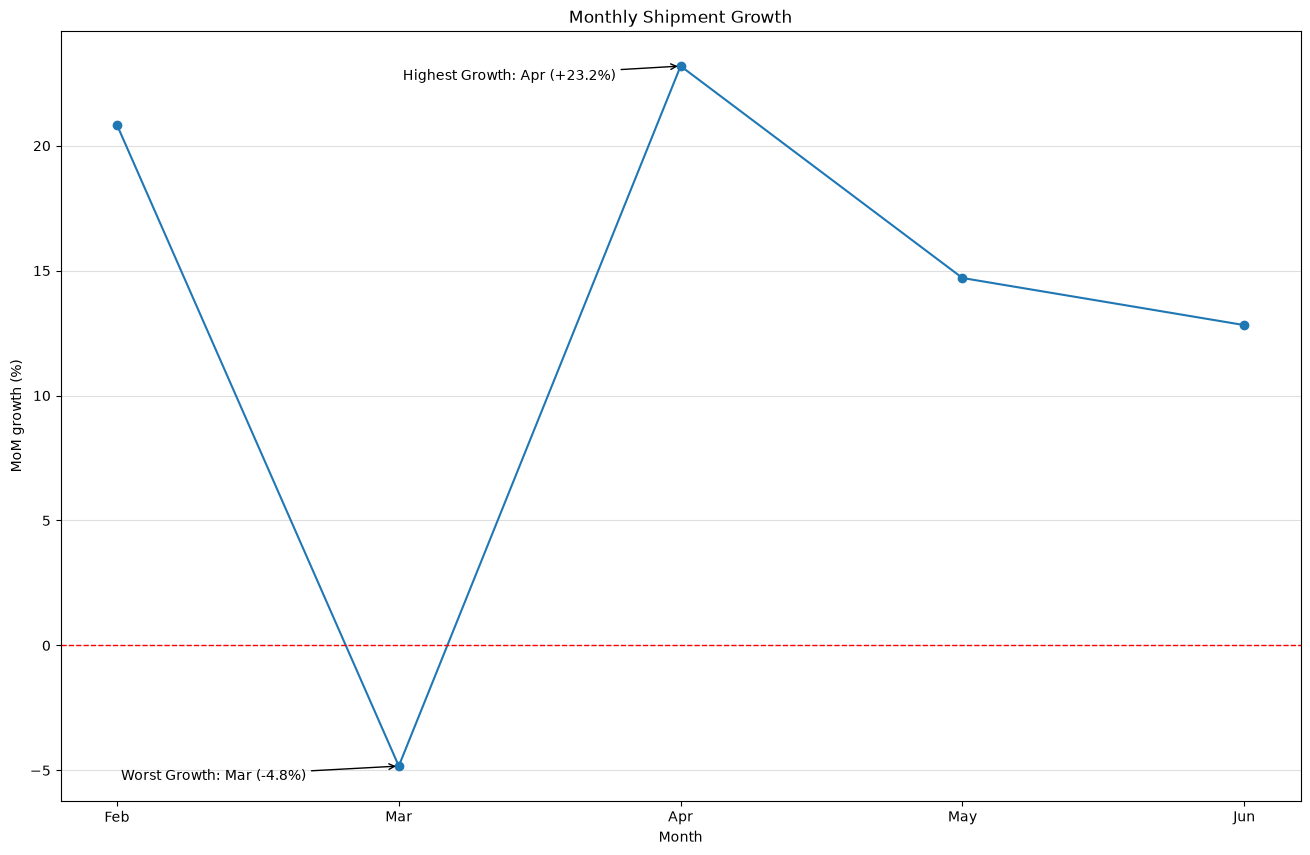

In [137]:
fig, ax = plt.subplots(figsize=(16,10))

ax.plot(
    growth_data["Month"],
    growth_data["MoM_Growth"],
    marker ="o",
    linestyle = "-",
)
ax.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=1
)

ax.grid(
    axis ="y",
    alpha=0.4
)

ax.annotate(
    (f"Highest Growth: {best_month['Month']} ({best_month['MoM_Growth']:+.1f}%)"),
    xy = (best_month["Month"],
          best_month["MoM_Growth"]),
    xytext=(-200, -10),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"}
)

ax.annotate(
    (f"Worst Growth: {worst_month['Month']} ({worst_month['MoM_Growth']:+.1f}%)"),
    xy = (worst_month["Month"],
          worst_month["MoM_Growth"]),
    xytext=(-200, -10),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"}
)

ax.set_title("Monthly Shipment Growth")
ax.set_xlabel("Month")
ax.set_ylabel("MoM growth (%)")

plt.show()

### 02.06.04 — Histograms & Distribution Analysis

In [138]:
import pandas as pd
import matplotlib.pyplot as plt

delivery_data = pd.DataFrame({
    "Delivery_Days": [
        1, 2, 2, 3, 2, 1, 3, 2, 4, 3,
        2, 3, 1, 2, 4, 3, 2, 5, 3, 2,
        1, 3, 2, 4, 3, 2, 5, 3, 2, 12
    ]
})

delivery_data.head()

,Delivery_Days
0,1
1,2
2,2
3,3
4,2


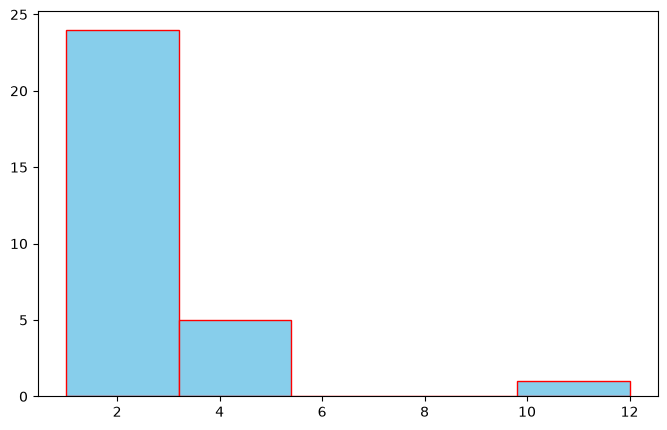

In [150]:
fig, ax = plt.subplots(figsize=(8,5))
ax.hist(
    delivery_data["Delivery_Days"],
    bins=5,
    color="skyblue",
    edgecolor="red"
)
plt.show()

### 02.06.04A — Your First Histogram

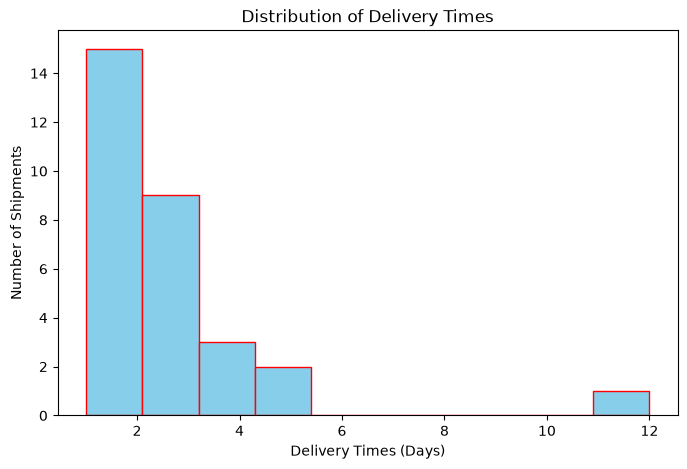

In [152]:
fig, ax = plt.subplots(figsize=(8,5))
ax.hist(
    delivery_data["Delivery_Days"],
    bins=10,
    color="skyblue",
    edgecolor="red"
)
ax.set_title("Distribution of Delivery Times")
ax.set_xlabel("Delivery Times (Days)")
ax.set_ylabel("Number of Shipments")

plt.show()

In [162]:
print(f"Mean Delivery: {delivery_data["Delivery_Days"].mean()}")
print(f"Median Delivery: {delivery_data["Delivery_Days"].median()}")
max_delivery = delivery_data["Delivery_Days"].max()
min_delivery = delivery_data["Delivery_Days"].min()

mean_delivery = delivery_data["Delivery_Days"].mean()
median_delivery = delivery_data["Delivery_Days"].median()

Mean Delivery: 2.9
Median Delivery: 2.5


### 02.06.04C — Visualizing Mean and Median

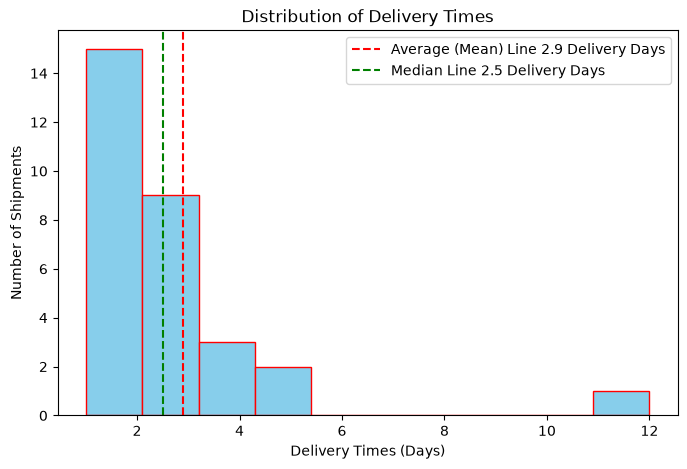

In [172]:
fig, ax = plt.subplots(figsize=(8,5))
ax.hist(
    delivery_data["Delivery_Days"],
    bins=10,
    color="skyblue",
    edgecolor="red"
)

ax.axvline(
    x=delivery_data["Delivery_Days"].mean(),
    color="red",
    linestyle="--",
    label=(f"Average (Mean) Line {mean_delivery} Delivery Days")
)

ax.axvline(
    x=delivery_data["Delivery_Days"].median(),
    color="green",
    linestyle="--",
    label=(f"Median Line {median_delivery} Delivery Days")
)
ax.legend()
ax.set_title("Distribution of Delivery Times")
ax.set_xlabel("Delivery Times (Days)")
ax.set_ylabel("Number of Shipments")

plt.show()

### 02.06.05 — Scatter Plots & Correlation Analysis

In [173]:
shipment_relationships = pd.DataFrame({
    "Weight_KG": [
        2, 5, 3, 8, 12, 6, 15, 4, 10, 18,
        7, 20, 14, 9, 25, 11, 16, 22, 13, 30
    ],
    "Delivery_Days": [
        1, 2, 1, 3, 3, 2, 4, 2, 3, 5,
        2, 5, 4, 3, 6, 3, 4, 5, 4, 7
    ]
})

shipment_relationships.head()

,Weight_KG,Delivery_Days
0,2,1
1,5,2
2,3,1
3,8,3
4,12,3


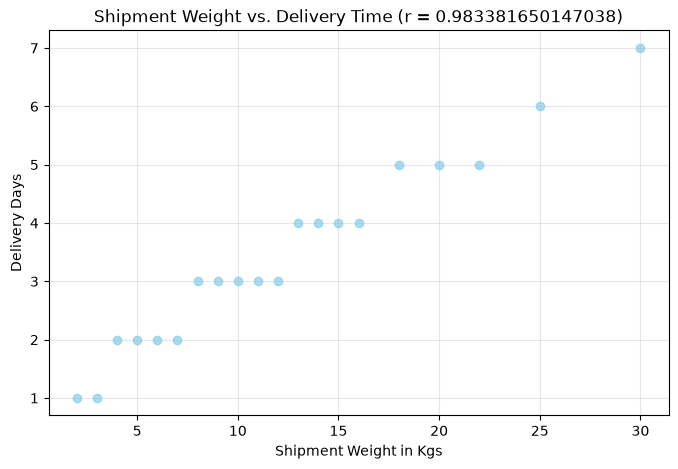

In [ ]:


fig, ax = plt.subplots(figsize=(8,5))
ax.scatter(
    shipment_relationships["Weight_KG"],
    shipment_relationships["Delivery_Days"],
    color = "skyblue",
    alpha = 0.7
)

ax.grid(
    alpha =0.3
)

ax.set_title(f"Shipment Weight vs. Delivery Time (r = {shipment_relationships["Weight_KG"].corr(shipment_relationships["Delivery_Days"])})")
ax.set_xlabel("Shipment Weight in Kgs")
ax.set_ylabel("Delivery Days")

plt.show()

### 02.06.05B — Correlation Analysis

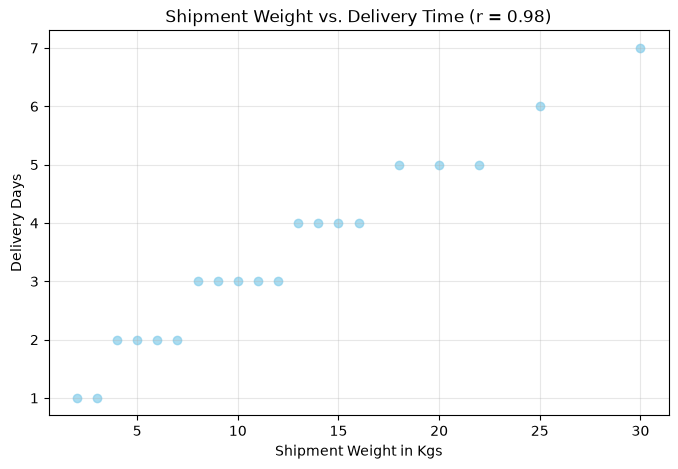

In [197]:
weight_delivery_corr = (shipment_relationships["Weight_KG"].corr(shipment_relationships["Delivery_Days"])).round(2)



fig, ax = plt.subplots(figsize=(8,5))
ax.scatter(
    shipment_relationships["Weight_KG"],
    shipment_relationships["Delivery_Days"],
    color = "skyblue",
    alpha = 0.7
)

ax.grid(
    alpha =0.3
)

ax.set_title(f"Shipment Weight vs. Delivery Time (r = {weight_delivery_corr})")
ax.set_xlabel("Shipment Weight in Kgs")
ax.set_ylabel("Delivery Days")

plt.show()

### Exercise 02.06.05C — Add a Regression Line

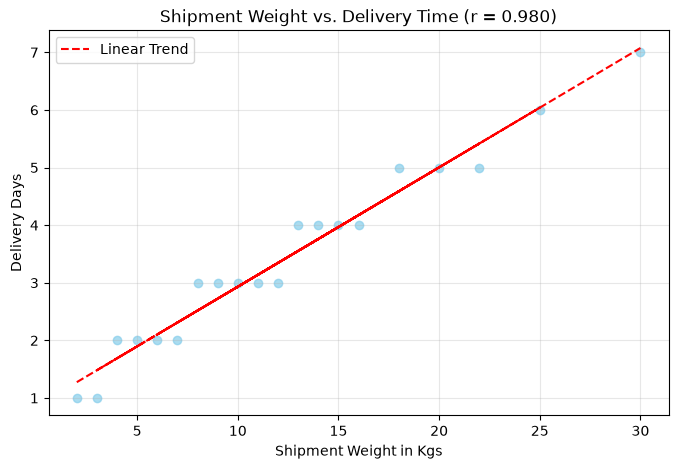

In [207]:
import numpy as np
slope, intercept = np.polyfit(
    shipment_relationships["Weight_KG"],
    shipment_relationships["Delivery_Days"],
    1
)

predicted_delivery = slope * shipment_relationships["Weight_KG"] + intercept

weight_delivery_corr = (shipment_relationships["Weight_KG"].corr(shipment_relationships["Delivery_Days"])).round(2)



fig, ax = plt.subplots(figsize=(8,5))
ax.scatter(
    shipment_relationships["Weight_KG"],
    shipment_relationships["Delivery_Days"],
    color = "skyblue",
    alpha = 0.7
)

ax.grid(
    alpha =0.3
)

ax.plot(
    shipment_relationships["Weight_KG"],
    predicted_delivery,
    color = "red",
    linestyle = "--",
    label="Linear Trend"
)

ax.legend()

ax.set_title(f"Shipment Weight vs. Delivery Time (r = {weight_delivery_corr:.3f})")
ax.set_xlabel("Shipment Weight in Kgs")
ax.set_ylabel("Delivery Days")

plt.show()

### 02.06.06 — Introduction to Seaborn

In [210]:
import seaborn as sns

shipment_relationships

,Weight_KG,Delivery_Days
0,2,1
1,5,2
2,3,1
3,8,3
4,12,3
5,6,2
6,15,4
7,4,2
8,10,3
9,18,5


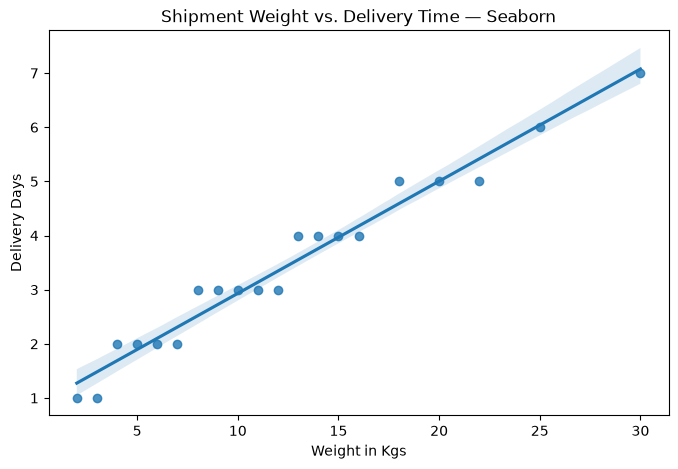

In [216]:
fig, ax = plt.subplots(figsize=(8,5))
sns.regplot(
    data = shipment_relationships,
    x = shipment_relationships["Weight_KG"],
    y = shipment_relationships["Delivery_Days"],
    ax=ax,
)
ax.set_title("Shipment Weight vs. Delivery Time — Seaborn"),
ax.set_xlabel("Weight in Kgs"),
ax.set_ylabel("Delivery Days")

plt.show()

### 02.06.06B — Distribution Analysis with Seaborn

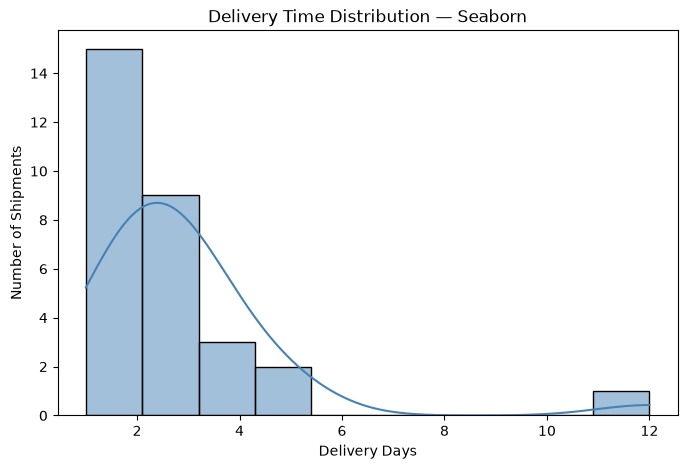

In [225]:
fig, ax = plt.subplots(figsize=(8,5))

ax.set_title("Delivery Time Distribution — Seaborn")
ax.set_xlabel("Delivery Days")
ax.set_ylabel("Number of Shipments")

sns.histplot(
    data=delivery_data,
    x="Delivery_Days",
    bins=10,
    kde=True,
    color ="steelblue",
)
plt.show()


### 02.06.07 — Professional Chart Customization

### Exercise 02.06.07A — Professionalizing Your Scatter Plot

In [226]:
shipment_relationships

,Weight_KG,Delivery_Days
0,2,1
1,5,2
2,3,1
3,8,3
4,12,3
5,6,2
6,15,4
7,4,2
8,10,3
9,18,5


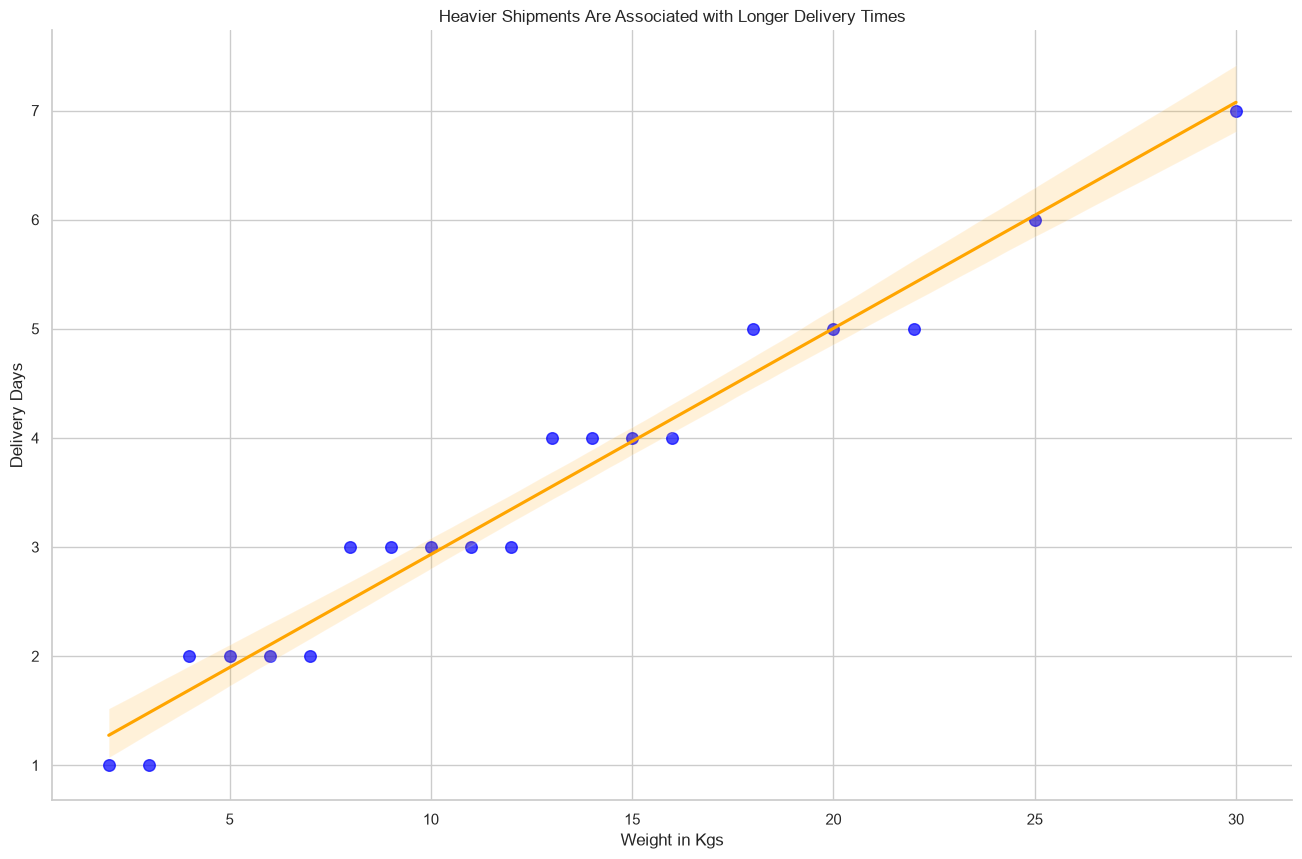

In [240]:
sns.set_theme(
    style="whitegrid",
)

fig, ax = plt.subplots(figsize=(16,10))

sns.regplot(
    data = shipment_relationships,
    x="Weight_KG",
    y="Delivery_Days",
    scatter_kws={
        "color":"blue",
        "alpha":0.7,
        "s":70
    },
    line_kws={
        "color":"orange",
        "alpha":1
    },
    ax=ax
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_title("Heavier Shipments Are Associated with Longer Delivery Times")
ax.set_xlabel("Weight in Kgs")
ax.set_ylabel("Delivery Days")

plt.show()

### 02.06.08 — Data Storytelling

### Exercise 02.06.08A — Build a KPI Summary

In [256]:
shipment_relationships

,Weight_KG,Delivery_Days
0,2,1
1,5,2
2,3,1
3,8,3
4,12,3
5,6,2
6,15,4
7,4,2
8,10,3
9,18,5


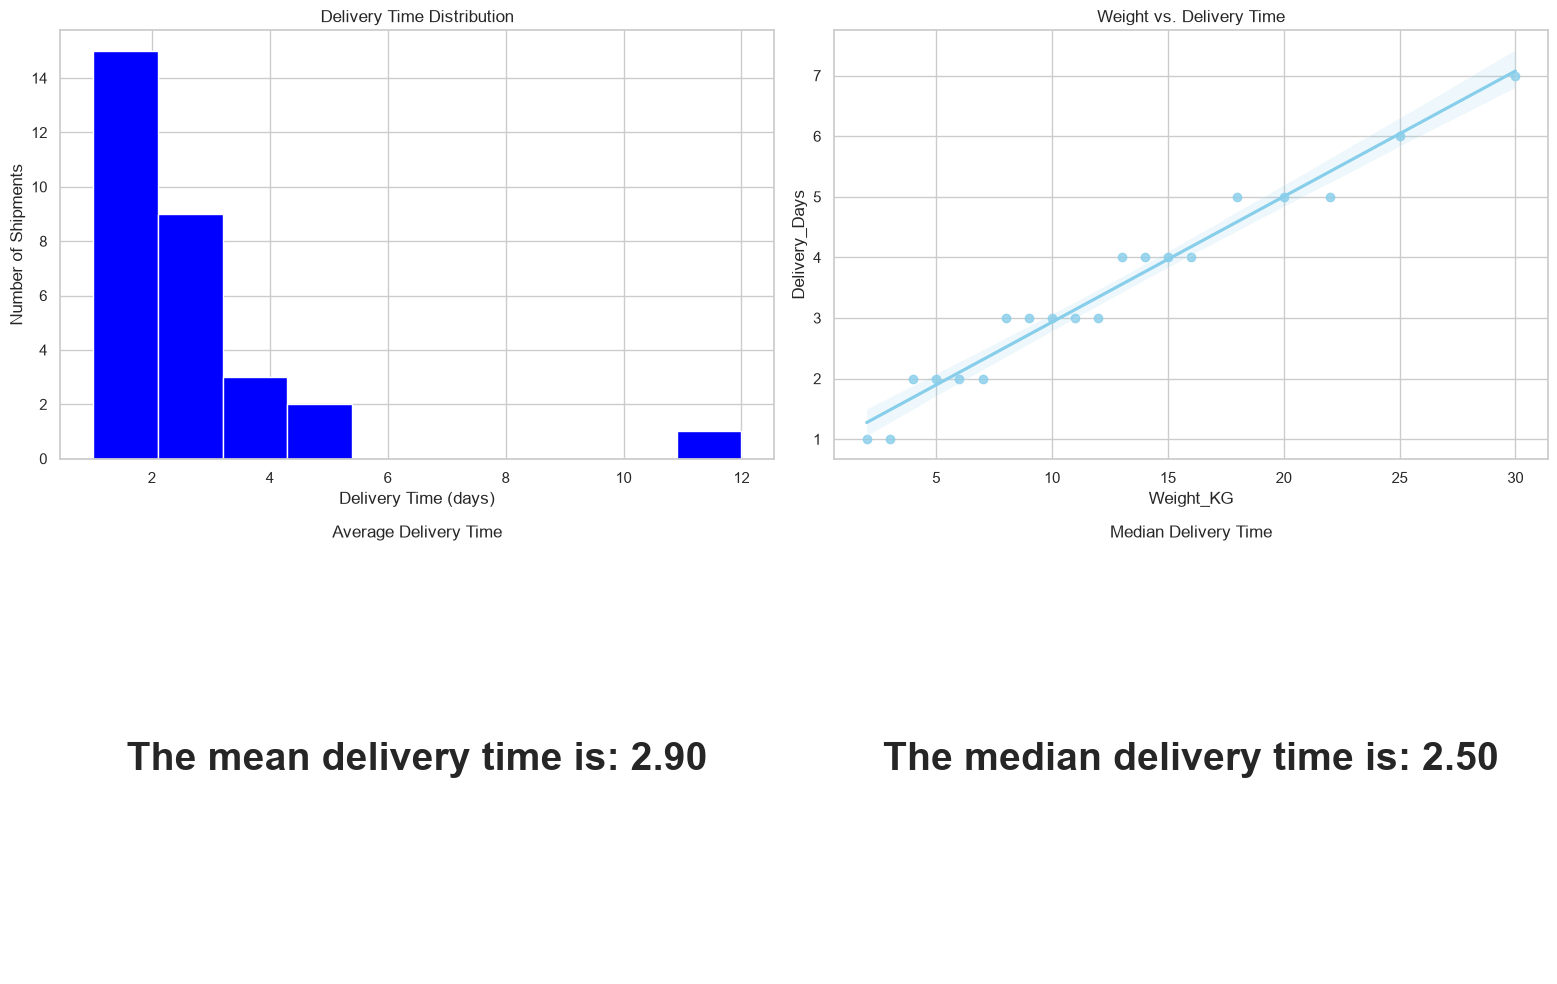

In [276]:
fig, ax = plt.subplots(
    ncols =2,
    nrows = 2,
    figsize=(16,10)
)

# Config Top Left Chart

ax[0,0].hist(
    delivery_data["Delivery_Days"],
    bins = 10,
    color = "blue",
)
ax[0, 0].set_title("Delivery Time Distribution")
ax[0, 0].set_xlabel("Delivery Time (days)")
ax[0, 0].set_ylabel("Number of Shipments")

# Config Top Right Chart

sns.regplot(
    data = shipment_relationships,
    x="Weight_KG",
    y="Delivery_Days",
    color = "skyblue",
    ax=ax[0,1]
)
ax[0, 1].set_title("Weight vs. Delivery Time")

# Config Bottom Left
mean_delivery = delivery_data["Delivery_Days"].mean()
median_delivery = delivery_data["Delivery_Days"].median()

ax[1,0].text(
    0.5,
    0.5,
    f"The mean delivery time is: {mean_delivery:.2f}",
    ha = "center",
    va = "center",
    fontsize =28,
    fontweight ="bold"
)
ax[1,0].set_title("Average Delivery Time")
ax[1,0].spines["top"].set_visible(False)
ax[1,0].spines["right"].set_visible(False)

# Config Bottom Right

ax[1,1].text(
    0.5,
    0.5,
    f"The median delivery time is: {median_delivery:.2f}",
    ha = "center",
    va = "center",
    fontsize =28,
    fontweight ="bold"
)
ax[1,1].set_title("Median Delivery Time")
ax[1,1].spines["top"].set_visible(False)
ax[1,1].spines["right"].set_visible(False)

ax[1, 0].axis("off")
ax[1, 1].axis("off")
plt.tight_layout()
plt.show()



## 02.06.10 — Final Visualization Challenge

In [277]:
customer_performance

,Customer,Total_Revenue,Avg_Revenue,Shipments,MoM_Growth
0,Amazon,2700,1350,2,NaN
1,Unknown,2000,2000,1,-50.0
2,Zalando,850,850,1,0.0
3,Otto,650,650,1,0.0


In [278]:
shipment_trends

,Month,Shipments,MoM_Growth
0,Jan,120,NaN
1,Feb,145,20.833333
2,Mar,138,-4.827586
3,Apr,170,23.188406
4,May,195,14.705882
5,Jun,220,12.820513


In [279]:
delivery_data

,Delivery_Days
0,1
1,2
2,2
3,3
4,2
5,1
6,3
7,2
8,4
9,3


In [280]:
shipment_relationships

,Weight_KG,Delivery_Days
0,2,1
1,5,2
2,3,1
3,8,3
4,12,3
5,6,2
6,15,4
7,4,2
8,10,3
9,18,5


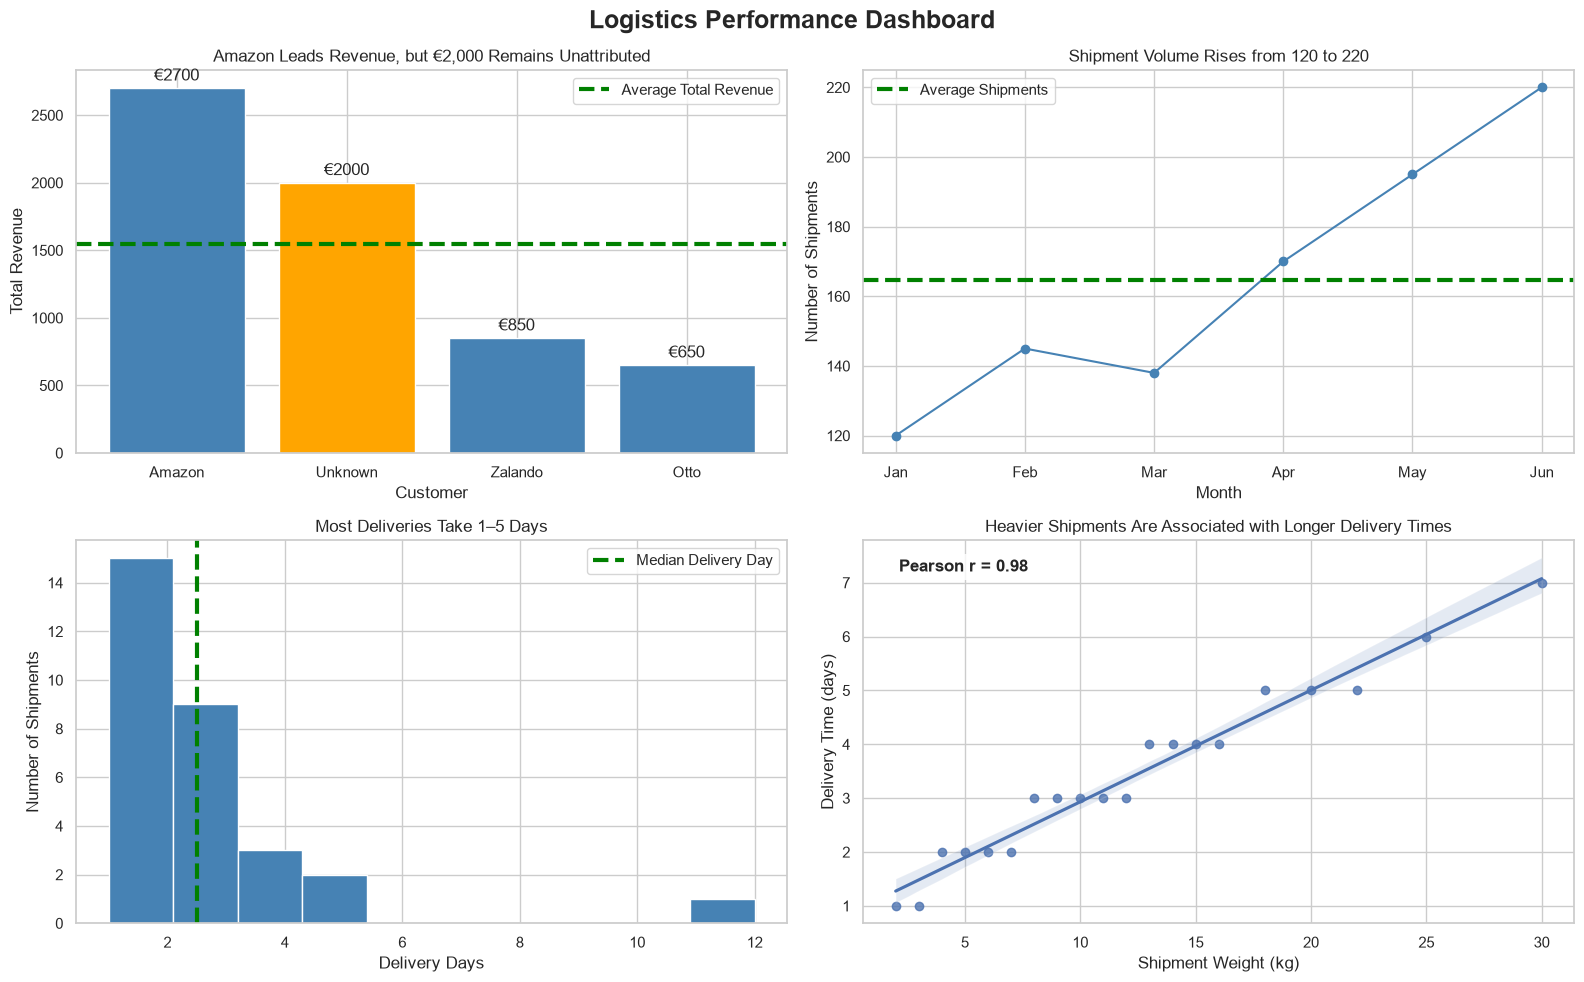

In [351]:
fig, ax = plt.subplots(
    nrows = 2,
    ncols = 2,
    figsize=(16,10)
)
# TOP LEFT
colors = ["orange" if customer == "Unknown" else "steelblue" for customer in customer_performance["Customer"]]
bars = ax[0,0].bar(
    customer_performance["Customer"],
    customer_performance["Total_Revenue"],
    color=colors
)

ax[0,0].bar_label(
    bars,
    fmt="€%.0f",
    padding=3
)

ax[0,0].set_title("Amazon Leads Revenue, but €2,000 Remains Unattributed")
ax[0,0].set_xlabel("Customer")
ax[0,0].set_ylabel("Total Revenue")
ax[0,0].axhline(
    y = customer_performance["Total_Revenue"].mean(),
    color = "green",
    linestyle = "--",
    linewidth = 3,
    label = "Average Total Revenue"
)
ax[0,0].legend()

# TOP RIGHT

ax[0,1].plot(
    shipment_trends["Month"],
    shipment_trends["Shipments"],
    color = "steelblue",
    marker = "o"
)
ax[0,1].set_title("Shipment Volume Rises from 120 to 220")
ax[0,1].set_xlabel("Month")
ax[0,1].set_ylabel("Number of Shipments")
ax[0,1].axhline(
    y = shipment_trends["Shipments"].mean(),
    color = "green",
    linestyle = "--",
    linewidth = 3,
    label = "Average Shipments"
)

ax[0,1].legend()

# BOTTOM RIGHT
correlation = shipment_relationships["Weight_KG"].corr(
    shipment_relationships["Delivery_Days"]
)
sns.regplot(
    data=shipment_relationships,
    x="Weight_KG",
    y="Delivery_Days",
    ax=ax[1,1]
)
ax[1,1].set_title("Heavier Shipments Are Associated with Longer Delivery Times")
ax[1,1].set_xlabel("Shipment Weight (kg)")
ax[1,1].set_ylabel("Delivery Time (days)")
ax[1, 1].text(
    0.05,
    0.95,
    f"Pearson r = {correlation:.2f}",
    transform=ax[1, 1].transAxes,
    fontsize=12,
    fontweight="bold",
    ha="left",
    va="top",
    bbox={
        "facecolor": "white",
        "alpha": 0.8,
        "edgecolor": "none"
    }
)

# BOTTOM LEFT 

ax[1,0].hist(
    delivery_data["Delivery_Days"],
    bins=10,
    color="steelblue"
)
ax[1,0].axvline(
    x = delivery_data["Delivery_Days"].median(),
    color = "green",
    linestyle = "--",
    linewidth = 3,
    label = "Median Delivery Day"
)
ax[1,0].legend()
ax[1,0].set_title("Most Deliveries Take 1–5 Days")
ax[1,0].set_xlabel("Delivery Days")
ax[1,0].set_ylabel("Number of Shipments")




fig.suptitle(

    "Logistics Performance Dashboard",

    fontsize=18,

    fontweight="bold"

)

plt.tight_layout()
plt.show()